# 04 · Train and validate

Same idea as the organisers' notebook 01, extended. Everything here uses **training data**,
plus the test answers of sub-01…04 **only to report a score** (never for the held-out subjects).

**Preprocessing** (`mindreading/preprocess.py`)
- 500 → 100 measurements per second (like the organisers).
- Normalise each file with its *own* statistics. The test files are scaled differently from
  the training files, so this matters.
- Keep a time window after the video starts.

**Two models** (`mindreading/models.py`), both PCA/ridge, both linear:
- **Encoder** (organisers' direction): video card → *predicted EEG*. Score a recording against a
  candidate video by correlating the real EEG with the EEG predicted for that video.
- **Decoder** (our direction): EEG → *predicted card*. Score by cosine similarity between the
  predicted card and each candidate's card.
- **Combined**: put both scores on the same scale and add them.

**Pooling**: by default one model is trained on the training recordings of **all 6 subjects**
(about 5,650 recordings). The rules allow this, including sub-05/06's *training* files.

In [1]:
import sys, json
from pathlib import Path
sys.path.insert(0, str(Path.cwd().parent))   # repo root, so `mindreading` imports work
import numpy as np
import matplotlib.pyplot as plt
from mindreading.config import DATA_DIR, RESULTS_DIR, WEIGHTS_DIR, SUBMISSION_DIR
print('data folder:', DATA_DIR)

data folder: C:\Users\canbe\Desktop\eeg-mind-reading-challenge\eeg-mind-reading-challenge


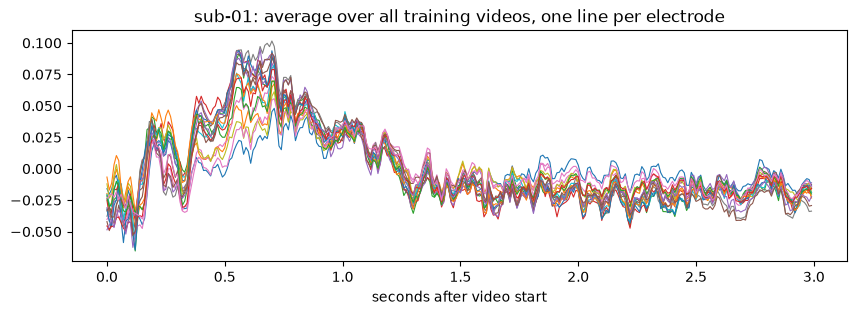

In [2]:
from mindreading.data import load_train
from mindreading.preprocess import downsample, normalise
ids, raw = load_train(1)
x = normalise(downsample(raw))
t = np.arange(x.shape[-1]) / 100
plt.figure(figsize=(10, 3))
plt.plot(t, x.mean(0).T, lw=0.8)
plt.title('sub-01: average over all training videos, one line per electrode')
plt.xlabel('seconds after video start'); plt.show()

### Choose the settings (on held-out training videos only)
`scripts/search_settings.py` hides 15% of the training videos, trains on the rest, and checks
how well the hidden ones are ranked. It tries different time windows, normalisations, pooled vs
per-subject models, and averaged vs per-frame cards. We load its results here, or run it if
they're missing.

In [3]:
import subprocess
path = RESULTS_DIR / 'settings_search.json'
if not path.exists():
    subprocess.run([sys.executable, str(Path.cwd().parent / 'scripts' / 'search_settings.py')], check=True)
search = json.loads(path.read_text())
print(f"{'setting':28s} {'encoder top5':>12s} {'decoder top5':>12s} {'combined top5':>13s}")
for name, r in search.items():
    s = r['scores']
    print(f"{name:28s} {s['encoder']['top5']:12.3f} {s['decoder']['top5']:12.3f} {s['combined']['top5']:13.3f}")
pairs = [(r['scores'][m]['top5'], name, m) for name, r in search.items() for m in r['scores']]
_, best_name, best_method = max(pairs)
print(f'\nchosen: {best_name!r} with the {best_method}')

setting                      encoder top5 decoder top5 combined top5
window 0-1s, pooled                 0.094        0.049         0.085
window 0-0.6s                       0.086        0.052         0.078
window 0-2s                         0.081        0.049         0.079
window 0-3s                         0.068        0.043         0.065
per-trial normalisation             0.078        0.047         0.067
per-subject models                  0.095        0.045         0.078
8 frames instead of mean            0.073        0.049         0.076

chosen: 'per-subject models' with the encoder


In [4]:
from mindreading.pipeline import Config, score_dev_test, summarise
from mindreading.video_features import extract_clip
chosen = dict(search[best_name]['config'])
if best_method != 'combined':
    chosen['methods'] = [best_method]          # train only the model that won
cfg = Config(**chosen)
(RESULTS_DIR / 'chosen_config.json').write_text(json.dumps(chosen, indent=2))
feats = extract_clip()
cfg

Config(tmin=0.0, tmax=1.0, norm='set', feature_key='mean', pool_subjects=False, methods=['encoder'], enc_pca=None, dec_pca=200, train_subjects=[1, 2, 3, 4, 5, 6], shuffle_labels=False)

### Score on the sub-01…04 test sets (102 candidates, chance = 1.0% top-1, 4.9% top-5)
The organisers' AlexNet baseline: about **4% top-1, 11.7% top-5**.

In [5]:
res = score_dev_test(cfg, feats)
for s, r in res.items():
    print(f'sub-0{s}: ' + '   '.join(f"{m} top1 {v['top1']:.3f} top5 {v['top5']:.3f}" for m, v in r.items()))
mean = summarise(res)
print('\nmean:   ' + '   '.join(f"{m} top1 {v['top1']:.3f} top5 {v['top5']:.3f}" for m, v in mean.items()))
(RESULTS_DIR / 'dev_test_scores.json').write_text(json.dumps({'per_subject': res, 'mean': mean}, indent=2))

sub-01: encoder top1 0.088 top5 0.343
sub-02: encoder top1 0.059 top5 0.206
sub-03: encoder top1 0.029 top5 0.206
sub-04: encoder top1 0.029 top5 0.176

mean:   encoder top1 0.051 top5 0.233


752

### Sanity check: shuffled labels must score at chance
We train again, but give every training recording a *random* video. If the score stays above
chance, something leaks (for example test data sneaking into training).

In [6]:
from dataclasses import replace
shuf = summarise(score_dev_test(replace(cfg, shuffle_labels=True), feats))
print('shuffled: ' + '   '.join(f"{m} top1 {v['top1']:.3f} top5 {v['top5']:.3f}" for m, v in shuf.items()))
print('chance:   top1 0.010 top5 0.049')

shuffled: encoder top1 0.015 top5 0.051
chance:   top1 0.010 top5 0.049
